# Ripple-carry arithmetic for order finding

This notebook builds an original Cuccaro-style carry chain and actual modular arithmetic. It compares the same N/a/exponent precision with the Fourier implementation. Sparse and Boolean simulations are bounded classical checks; physical results are conditional QDK model projections. Python3.12 and the pinned public code package are required.

In [1]:
from pathlib import Path
import sys, os
root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
if (root / "src").exists():
    sys.path.insert(0, str(root / "src"))
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from openquantum.shor import build_order_finding_circuit, decompose, success_contract
from openquantum.shor_ripple import (
    ripple_adder_gate, controlled_multiplier_gate_ripple,
    build_order_finding_circuit_ripple, simulate_boolean_batch,
    sparse_statevector, simulate_order_finding_ripple,
)

## A real two-bit carry circuit

The first two wires hold a, the next two b, and the last the preserved carry input. MAJ propagates carries; reverse UMA restores a and the carry while leaving b+a+carry modulo4. This deliberately simple implementation uses2m Toffolis and4m CNOTs, rather than claiming the paper’s optimized endpoints.

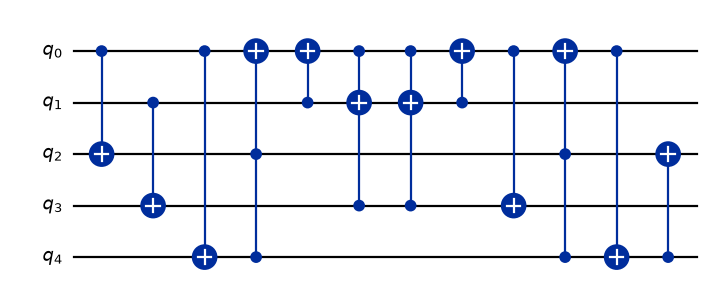

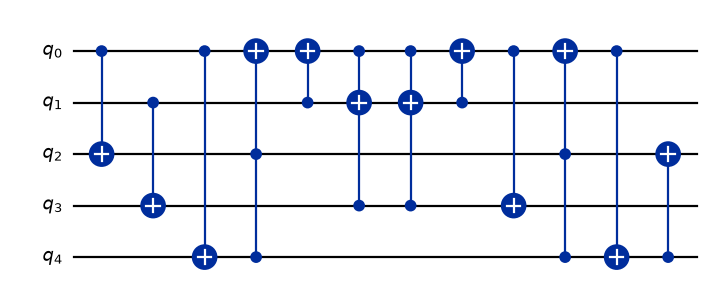

In [2]:
adder = QuantumCircuit(5)
adder.append(ripple_adder_gate(2), range(5))
adder.decompose().draw(output="mpl", fold=32, scale=0.8)

In [3]:
basis_inputs = [a + (b << 2) + (carry << 4)
                for a in range(4) for b in range(4) for carry in (0, 1)]
expected = [a + (((a+b+carry) % 4) << 2) + (carry << 4)
            for a in range(4) for b in range(4) for carry in (0, 1)]
assert simulate_boolean_batch(adder, basis_inputs) == expected
{"checked_all_basis_inputs": len(basis_inputs), "a_and_carry_restored": True}

{'checked_all_basis_inputs': 32, 'a_and_carry_restored': True}

## Actual modular multiplication and coherent control

Constant-register preparation is controlled with X/CX/CCX. The ripple adder restores the constant register, which is unprepared before its next use. Borrow cleanup and inverse multiplication are included. The extra work register trades space for fewer general-angle rotations.

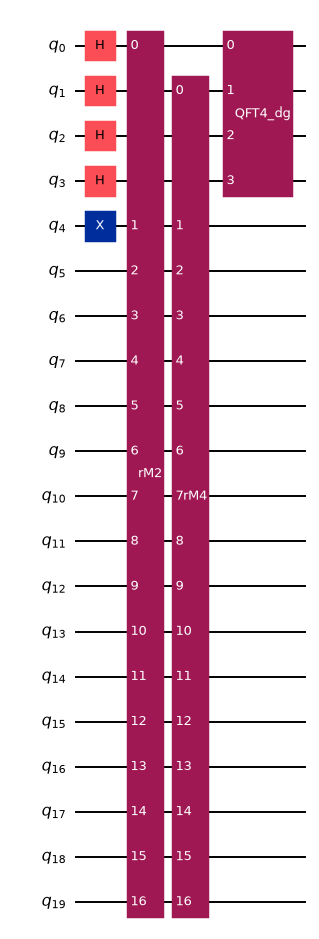

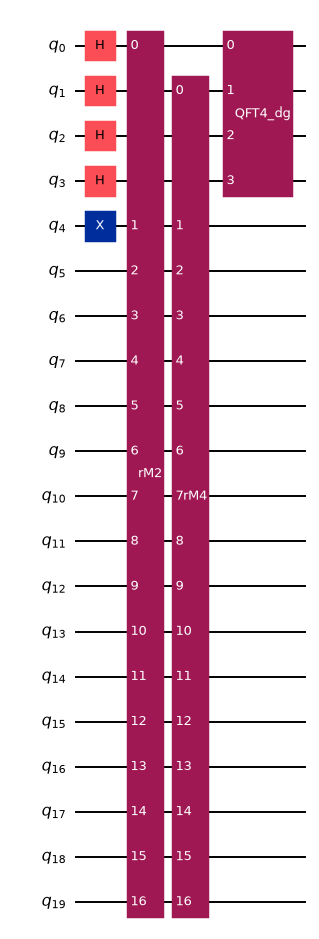

In [4]:
N, a, t = 15, 2, 4
source = build_order_finding_circuit_ripple(N, a, t)
source.draw(output="mpl", fold=36, scale=0.7)

In [5]:
# Actual small complex-state check, independent of the Boolean interpreter.
gate = controlled_multiplier_gate_ripple(5, 2)
coherent = QuantumCircuit(gate.num_qubits)
coherent.h(0)
coherent.s(0)
coherent.x(1)
coherent.append(gate, range(gate.num_qubits))
actual = Statevector.from_instruction(coherent).data
expected = np.zeros_like(actual)
expected[2], expected[5] = 1/np.sqrt(2), 1j/np.sqrt(2)
assert np.max(np.abs(actual - expected)) < 1e-13
{"maximum_complex_amplitude_error": float(np.max(np.abs(actual - expected))), "work_clean_and_relative_phase_preserved": True}

{'maximum_complex_amplitude_error': 0.0,
 'work_clean_and_relative_phase_preserved': True}

## Full sparse circuit checks

The source simulator applies every H/phase and Boolean primitive to complex amplitudes. It does not substitute a classical modular-power matrix or truncate amplitudes. The independent reference uses classical order only for validation. N21 uses25 source wires, avoiding a dense512MiB amplitude array by sparse support and explicit work caps.

In [6]:
first = simulate_order_finding_ripple(15, 2, 4)
second = simulate_order_finding_ripple(21, 2, 6)
assert first["maximum_probability_error"] < 1e-10
assert second["maximum_probability_error"] < 1e-10
assert first["dirty_work_probability"] == second["dirty_work_probability"] == 0
[{key: result[key] for key in ("modulus", "total_qubits", "maximum_probability_error", "dirty_work_probability", "peak_nonzero_amplitudes", "source_gate_state_applications")}
 for result in (first, second)]

[{'modulus': 15,
  'total_qubits': 20,
  'maximum_probability_error': 3.3306690738754696e-16,
  'dirty_work_probability': 0.0,
  'peak_nonzero_amplitudes': 16,
  'source_gate_state_applications': 45564},
 {'modulus': 21,
  'total_qubits': 25,
  'maximum_probability_error': 3.0531133177191805e-16,
  'dirty_work_probability': 0.0,
  'peak_nonzero_amplitudes': 380,
  'source_gate_state_applications': 818384}]

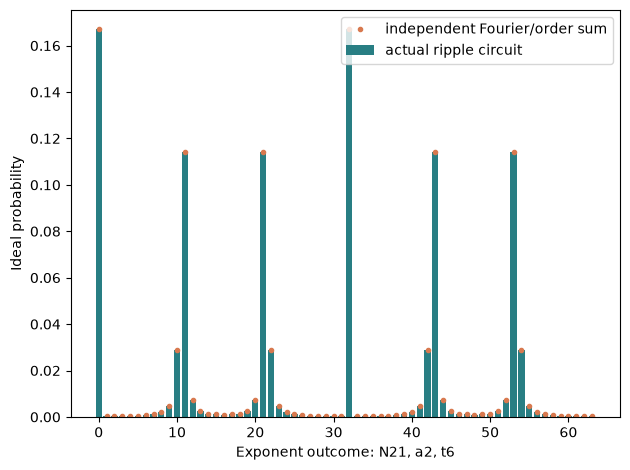

In [7]:
plt.bar(np.arange(1 << 6), second["probabilities"], color="#287e83", label="actual ripple circuit")
plt.plot(np.arange(1 << 6), second["reference_probabilities"], ".", color="#d8794f", label="independent Fourier/order sum")
plt.xlabel("Exponent outcome: N21, a2, t6")
plt.ylabel("Ideal probability")
plt.legend(); plt.tight_layout(); plt.show()

## Equal-task logical comparison

Both circuits use the same classical input, initial modular value1, exponent precision and readout rule. Counts include all work registers, constant handling, inverses, state preparation and final measurements. More total gates can still mean fewer synthesized rotations; a physical comparison requires its own matched model.

In [8]:
rows = []
for N, a, t in [(15, 2, 4), (21, 2, 6)]:
    trials = success_contract(N, a, t)["serial_trials"]
    for name, builder in [("Fourier", build_order_finding_circuit), ("ripple", build_order_finding_circuit_ripple)]:
        compiled = decompose(builder(N, a, t, measure=True))
        rows.append({"N": N, "a": a, "t": t, "method": name,
                     "logical_qubits": compiled.num_qubits, "primitive_operations": int(sum(compiled.count_ops().values())),
                     "rx_ry_rz_operations": int(sum(compiled.count_ops().get(k, 0) for k in ("rx", "ry", "rz"))),
                     "dependency_depth": compiled.depth(), "complete_trials": trials,
                     "all_trials_primitive_operations": int(sum(compiled.count_ops().values())) * trials})
rows

[{'N': 15,
  'a': 2,
  't': 4,
  'method': 'Fourier',
  'logical_qubits': 14,
  'primitive_operations': 8669,
  'rx_ry_rz_operations': 4388,
  'dependency_depth': 4994,
  'complete_trials': 8,
  'all_trials_primitive_operations': 69352},
 {'N': 15,
  'a': 2,
  't': 4,
  'method': 'ripple',
  'logical_qubits': 20,
  'primitive_operations': 16473,
  'rx_ry_rz_operations': 121,
  'dependency_depth': 9978,
  'complete_trials': 8,
  'all_trials_primitive_operations': 131784},
 {'N': 21,
  'a': 2,
  't': 6,
  'method': 'Fourier',
  'logical_qubits': 18,
  'primitive_operations': 45276,
  'rx_ry_rz_operations': 23220,
  'dependency_depth': 23665,
  'complete_trials': 16,
  'all_trials_primitive_operations': 724416},
 {'N': 21,
  'a': 2,
  't': 6,
  'method': 'ripple',
  'logical_qubits': 25,
  'primitive_operations': 74260,
  'rx_ry_rz_operations': 512,
  'dependency_depth': 45004,
  'complete_trials': 16,
  'all_trials_primitive_operations': 1188160}]

## Optional live controls

In a live kernel, select a bounded case to regenerate the actual ripple circuit and its computed probability plot. Static publication omits kernel-backed controls. The live kernel is local or Binder; GitHub Pages needs no maintained server.

In [9]:
def explore_ripple(case):
    N, a, t = case
    result = simulate_order_finding_ripple(N, a, t)
    contract = success_contract(N, a, t)
    print({"N": N, "a": a, "phase_bits": t, "wires": result["total_qubits"], "distribution_validation_error": result["maximum_probability_error"], "ideal_factor_success": contract["ideal_factoring_success_probability_per_trial"], "complete_trials": contract["serial_trials"]})
    plt.bar(np.arange(1 << t), result["probabilities"], color="#287e83")
    plt.xlabel("Exponent outcome"); plt.ylabel("Ideal probability"); plt.show()
    display(build_order_finding_circuit_ripple(N, a, t).draw(output="mpl", fold=36, scale=0.6))

if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    from IPython.display import display
    import ipywidgets as widgets
    widgets.interact(explore_ripple, case=widgets.Dropdown(options={
        "N15, a2, t4": (15, 2, 4),
        "N15, a7, t4": (15, 7, 4),
        "N21, a2, t4": (21, 2, 4),
        "N21, a2, t6": (21, 2, 6),
    }))

## Reproduce and scale separately

`python scripts/generate_shor_ripple.py --physical` emits real QASM, source hashes, sparse checks, a circuit-only scaling table and a matched conditional surface-code comparison. `--dense-check --no-extra` optionally repeats the slow full N15 Qiskit check. `--modulus 33 --base 2 --phase-bits 12 --no-sim --no-extra --output-dir artifacts/ripple33` generates larger circuits without a quantum amplitude simulation. Source generation and quantum simulation have distinct caps. No Lean proof is claimed.